# Poređenje optimizovanih modela: CIFAR-10

Poredi se 5 verzija modela sa hiperparametrima iz Optune (`_tuned`). Protokol: 5-fold stratifikovana cross-validacija nad 45.000 slika, 10 epoha, seed 42. Svaki fold-model je dodatno ocenjen na 5.000 test slika koje nikad nisu korišćene ni u treningu ni u tuningu.

Learning curves, konfuzione matrice i ROC/PR krive računate su nad validacionim fold-ovima, a ne nad test skupom.

## 1. Učitavanje rezultata

In [ ]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml
from sklearn.metrics import (auc, average_precision_score,
                             precision_recall_curve, roc_curve)

ROOT = Path("..")
RUNS = ROOT / "results" / "runs"
OUT = ROOT / "results" / "comparison"
OUT.mkdir(parents=True, exist_ok=True)

CLASSES = ["airplane", "automobile", "bird", "cat", "deer",
           "dog", "frog", "horse", "ship", "truck"]
TUNED = ["mlp_tuned", "cnn_tuned", "cnn_bn_tuned", "cnn_bn_aug_tuned", "resnet_tuned"]

summary = {n: json.loads((RUNS / n / "summary.json").read_text()) for n in TUNED}
folds = {n: pd.read_csv(RUNS / n / "fold_metrics.csv") for n in TUNED}
history = {n: pd.read_csv(RUNS / n / "history.csv") for n in TUNED}
print("Ucitano modela:", len(TUNED))

## 2. Glavna tabela
Prosečne metrike (± std preko fold-ova), vreme treniranja i inferencije, veličina modela i resursi.

In [ ]:
rows = []
for n in TUNED:
    s = summary[n]
    rows.append({
        "model": n,
        "params": s["n_params"],
        "size_MB": round(s["model_size_mb"], 2),
        "cv_acc": f'{s["accuracy_mean"]:.4f} ± {s["accuracy_std"]:.4f}',
        "cv_macro_f1": f'{s["macro_f1_mean"]:.4f} ± {s["macro_f1_std"]:.4f}',
        "test_acc": f'{s["test_accuracy_mean"]:.4f} ± {s["test_accuracy_std"]:.4f}',
        "test_macro_f1": f'{s["test_macro_f1_mean"]:.4f} ± {s["test_macro_f1_std"]:.4f}',
        "train_time_s": round(s["total_train_time_s"]),
        "infer_ms_per_img": round(s["inference_ms_per_image_mean"], 4),
        "peak_RAM_MB": round(s["peak_ram_mb_mean"]),
    })
table = pd.DataFrame(rows).set_index("model")
table.to_csv(OUT / "comparison_table.csv")
table

**Zaključak:** MLP je najslabiji (53%), a konvolucione mreže su između 73 i 77%. ResNet je najmanji model (309 hiljada parametara, 1,2 MB), ali najsporiji za treniranje (oko 3.100 s) i inferenciju (oko 0,6 ms po slici). MLP je najveći (6,5 MB), a najbrži.

## 3. Metrike po fold-u
Validaciona i test tačnost za svaki fold i prosek.

In [ ]:
val = pd.DataFrame({n: folds[n].set_index("fold")["accuracy"] for n in TUNED}).T
tst = pd.DataFrame({n: folds[n].set_index("fold")["test_accuracy"] for n in TUNED}).T
for t in (val, tst):
    t.columns = [f"fold {c}" for c in t.columns]
    t["mean"] = t.mean(axis=1)
print("Validaciona tačnost po fold-u:")
display(val.round(4))
print("Test tačnost po fold-u (svaki fold-model ocenjen na istih 5.000 slika):")
display(tst.round(4))

**Zaključak:** razlike između fold-ova su male (najveća kod `cnn_bn_tuned`, oko 1,5 poena), pa su prosečne vrednosti pouzdane.

## 4. CV naspram test skupa

In [ ]:
cv = [summary[n]["accuracy_mean"] for n in TUNED]
te = [summary[n]["test_accuracy_mean"] for n in TUNED]
te_std = [summary[n]["test_accuracy_std"] for n in TUNED]
x = np.arange(len(TUNED))
w = 0.38
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(x - w / 2, cv, w, color="lightsteelblue", label="CV (validacija)")
ax.bar(x + w / 2, te, w, yerr=te_std, capsize=3, color="steelblue", label="Test (5.000 slika)")
ax.set_xticks(x)
ax.set_xticklabels(TUNED, rotation=30, ha="right")
ax.set_ylim(0.4, 0.85)
ax.set_ylabel("Tačnost")
ax.set_title("Optimizovane verzije: CV i test tačnost")
ax.legend()
plt.tight_layout()
plt.savefig(OUT / "test_accuracy.png", dpi=150)
plt.show()

**Zaključak:** poredak na test skupu je ResNet (76,9%), CNN+BN (76,1%), CNN+BN+augmentacija (74,6%), CNN (73,2%) i MLP (53,3%), isti kao po CV tačnosti. Test brojke su za 0,03 do 0,6 poena veće od CV, pa nema znakova preprilagođavanja. ResNet i CNN+BN se razlikuju manje od 1 poena, što je u granicama šuma (5.000 slika daje standardnu grešku od oko 0,6 poena).

## 5. Najbolji hiperparametri iz Optune

In [5]:
hp = []
for n in TUNED:
    c = yaml.safe_load((RUNS / n / "config.yaml").read_text())
    hp.append({"model": n, "optimizer": c["optimizer"], "lr": round(c["lr"], 5),
               "batch_size": c["batch_size"], "weight_decay": c["weight_decay"],
               "dropout": c["model_params"].get("dropout", "-")})
pd.DataFrame(hp).set_index("model")

,optimizer,lr,batch_size,weight_decay,dropout
model,,,,,
mlp_tuned,adam,0.00013,64,0.000051,-
cnn_tuned,sgd,0.00406,64,0.000280,-
cnn_bn_tuned,sgd,0.00731,128,0.000015,0.246545
cnn_bn_aug_tuned,sgd,0.02911,64,0.000002,0.44647
resnet_tuned,adam,0.00869,128,0.000001,-


**Zaključak:** za sve tri CNN varijante Optuna je izabrala SGD, a za MLP i ResNet Adam.

## 6. Learning curves
Prosek preko 5 fold-ova, po epohama.

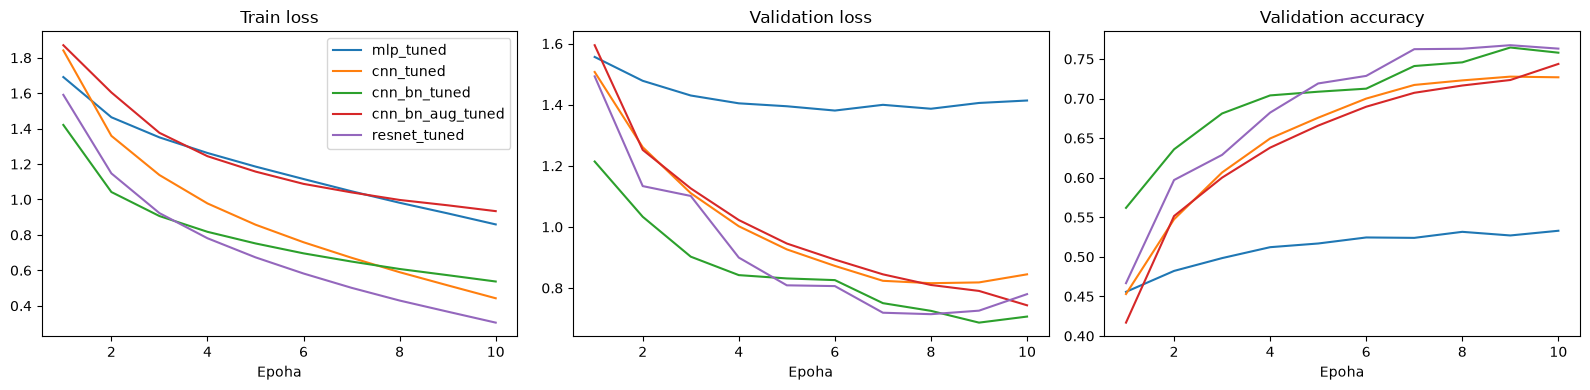

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for n in TUNED:
    h = history[n].groupby("epoch")[["train_loss", "val_loss", "val_acc"]].mean()
    ax[0].plot(h.index, h["train_loss"], label=n)
    ax[1].plot(h.index, h["val_loss"], label=n)
    ax[2].plot(h.index, h["val_acc"], label=n)
for a, t in zip(ax, ["Train loss", "Validation loss", "Validation accuracy"]):
    a.set_title(t)
    a.set_xlabel("Epoha")
ax[0].legend()
plt.tight_layout()
plt.savefig(OUT / "learning_curves.png", dpi=150)
plt.show()

**Zaključak:** MLP validacioni gubitak stane oko 1,4 iako trening gubitak pada. ResNet ima najniži trening gubitak i najveći razmak prema validaciji, a `cnn_bn` najniži validacioni gubitak. Kod `cnn_bn_aug` trening gubitak je najviši zbog augmentacije, a validaciona tačnost još raste u 10. epohi, pa bi dobio sa više epoha.

## 7. Konfuzione matrice
Zbir preko svih fold-ova, normalizovano po stvarnoj klasi.

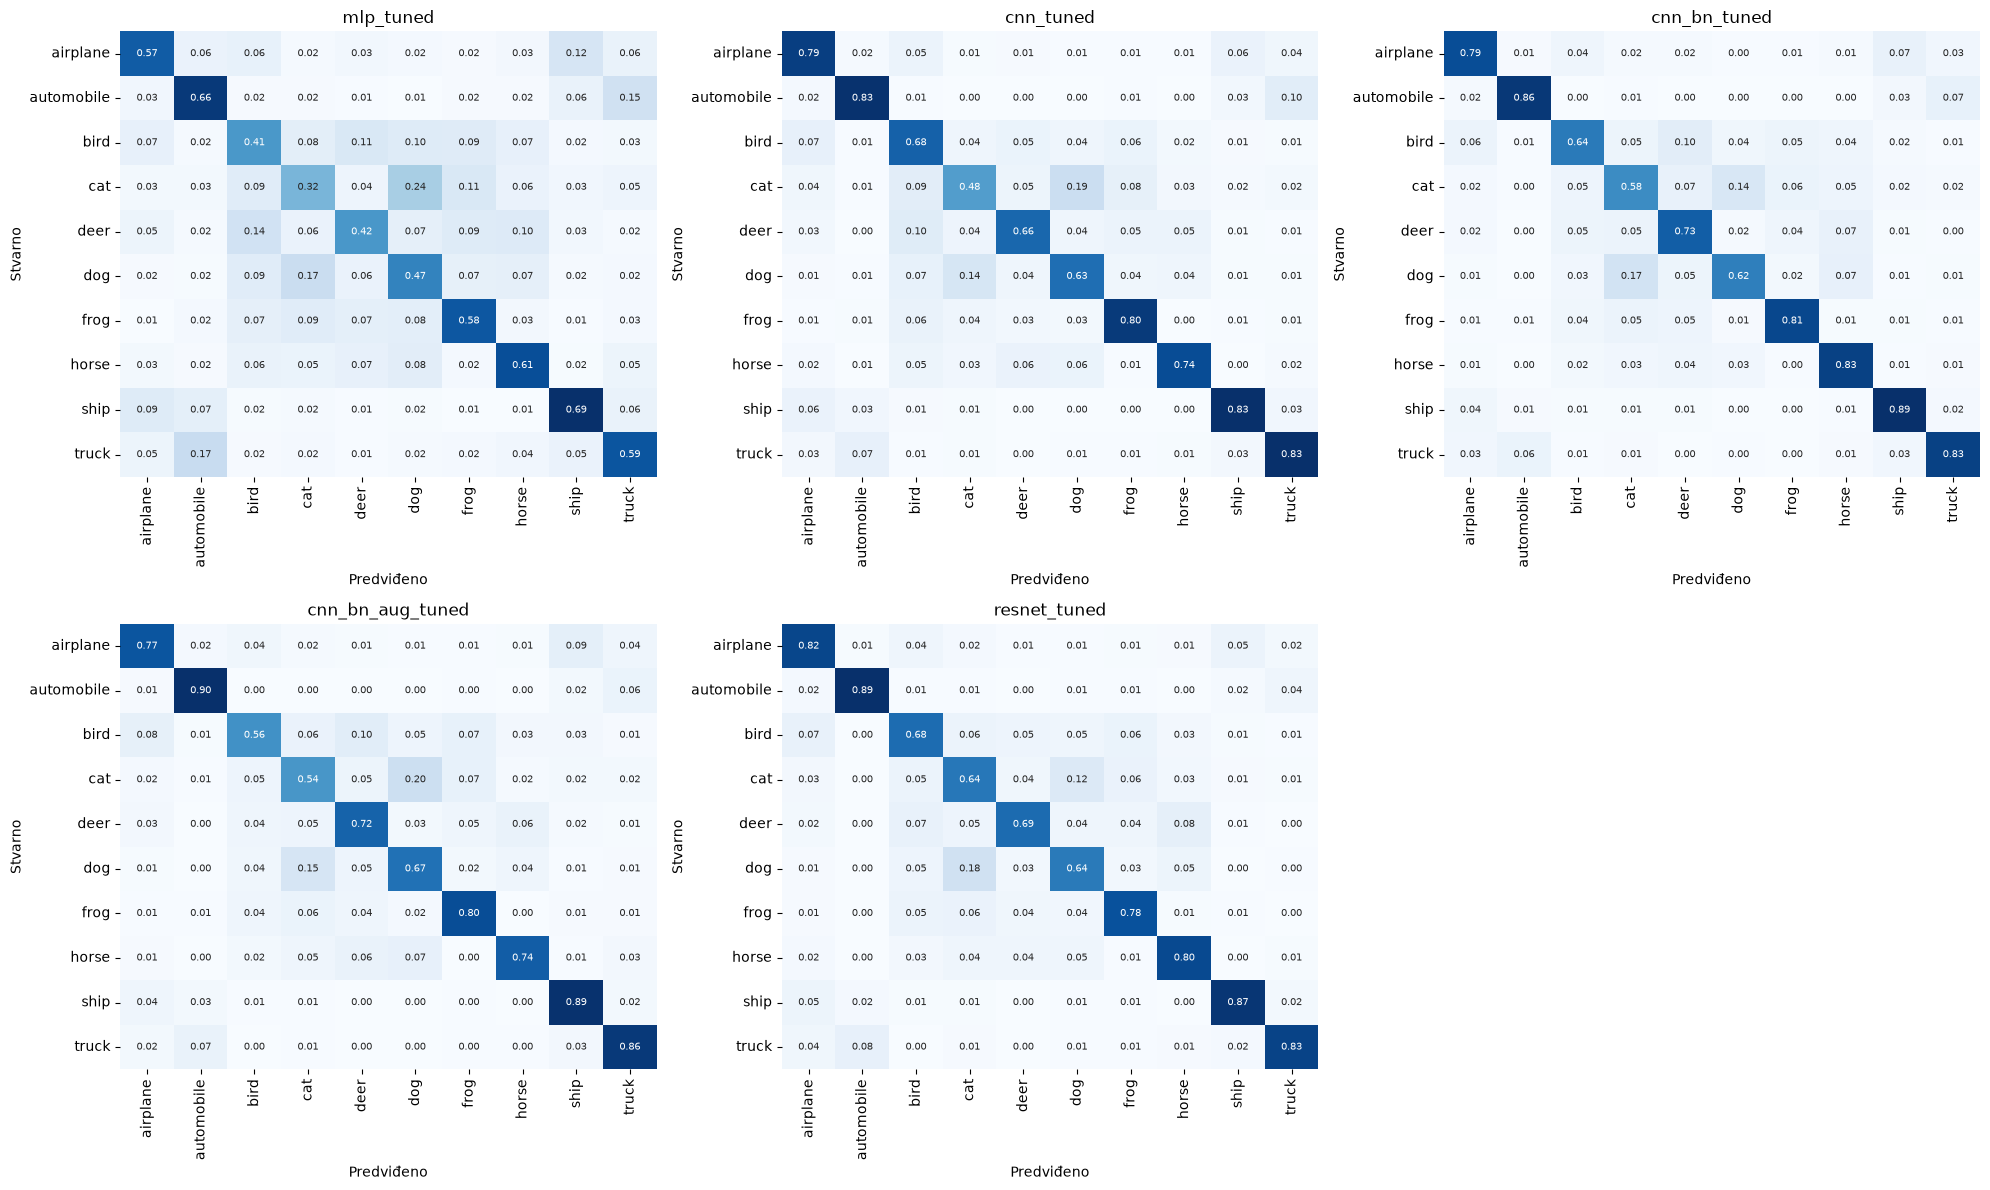

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
for ax, n in zip(axes.ravel(), TUNED):
    cm = sum(pd.read_csv(RUNS / n / f"confusion_matrix_fold{k}.csv").to_numpy()
             for k in range(1, 6))
    cmn = cm / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Blues", cbar=False,
                xticklabels=CLASSES, yticklabels=CLASSES, ax=ax,
                annot_kws={"size": 7})
    ax.set_title(n)
    ax.set_xlabel("Predviđeno")
    ax.set_ylabel("Stvarno")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.savefig(OUT / "confusion_matrices.png", dpi=120)
plt.show()

**Zaključak:** najlakše su automobile, ship, truck i airplane (80 do 90% kod konvolucionih modela). Najteža je klasa cat (48 do 64%, kod MLP-a 32%), najčešće zamenjena sa dog. Česta je i greška truck i automobile.

## 8. ROC i PR krive
Micro-prosek preko svih 10 klasa.

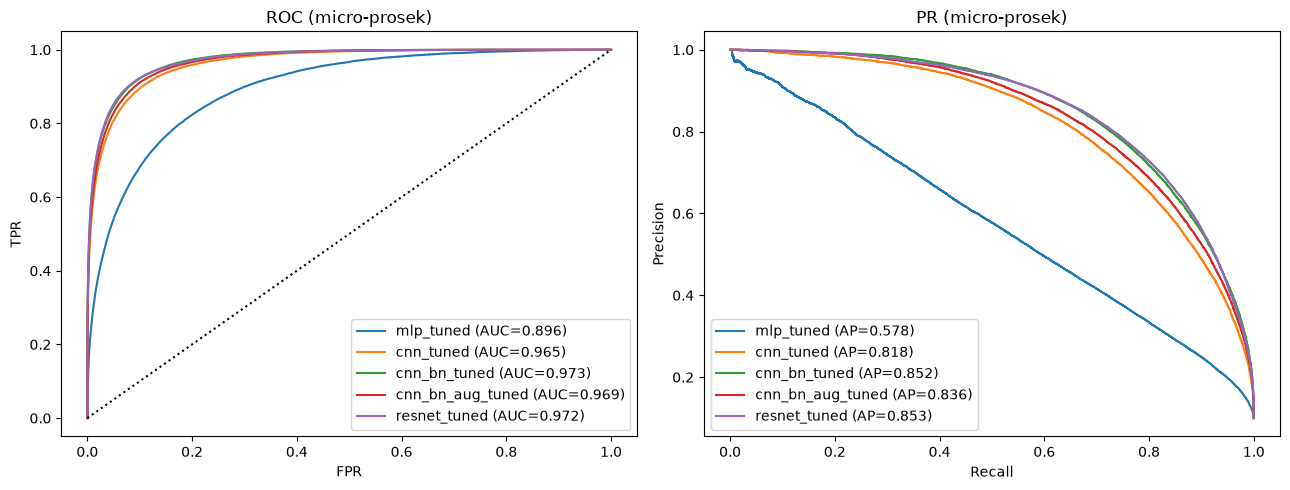

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for n in TUNED:
    d = np.load(RUNS / n / "oof_predictions.npz")
    Y = np.eye(10)[d["y"]].ravel()
    P = d["probs"].ravel()
    fpr, tpr, _ = roc_curve(Y, P)
    ax[0].plot(fpr, tpr, label=f"{n} (AUC={auc(fpr, tpr):.3f})")
    prec, rec, _ = precision_recall_curve(Y, P)
    ax[1].plot(rec, prec, label=f"{n} (AP={average_precision_score(Y, P):.3f})")
ax[0].plot([0, 1], [0, 1], "k:")
ax[0].set(title="ROC (micro-prosek)", xlabel="FPR", ylabel="TPR")
ax[1].set(title="PR (micro-prosek)", xlabel="Recall", ylabel="Precision")
ax[0].legend()
ax[1].legend()
plt.tight_layout()
plt.savefig(OUT / "roc_pr_curves.png", dpi=150)
plt.show()

**Zaključak:** MLP je daleko iza (AUC 0,896, AP 0,578), a konvolucione verzije su blizu: AUC 0,965 do 0,973 i AP 0,818 do 0,853. Najviši AUC ima `cnn_bn_tuned`, a najviši AP `resnet_tuned`.

## 9. Vreme, inferencija, veličina modela i resursi

In [ ]:
panels = [("total_train_time_s", "Ukupno vreme treniranja (s)"),
          ("inference_ms_per_image_mean", "Inferencija (ms po slici)"),
          ("model_size_mb", "Veličina modela (MB)"),
          ("peak_ram_mb_mean", "Vrh RAM-a (MB)")]
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for a, (col, title) in zip(ax, panels):
    a.bar(TUNED, [summary[n][col] for n in TUNED], color="steelblue")
    a.set_title(title)
    a.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.savefig(OUT / "resources.png", dpi=150)
plt.show()

**Zaključak:** trening vreme raste od MLP-a (oko 3 minuta) preko CNN varijanti (12 do 15 minuta) do ResNeta (oko 52 minuta), a inferencija prati isti redosled. Veličina modela ne prati brzinu: ResNet je najmanji, a MLP najveći. Merenja su rađena na CPU-u (AMD Ryzen, 12 niti).

## Sažetak

- Najbolji na test skupu je `resnet_tuned` (76,9%), ali je praktično izjednačen sa `cnn_bn_tuned` (76,1%), koji se trenira oko tri puta brže.
- MLP je daleko najslabiji, pa konvolucije donose oko 20 procentnih poena.
- Test brojke su bliske CV brojkama, pa su rezultati stabilni.
- Najčešće greške su cat i dog, te truck i automobile.